In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import set_config
from sklearn.preprocessing import(
OneHotEncoder,
StandardScaler
)
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay,
    classification_report,
    recall_score,
    f1_score,
    precision_score
)
import warnings; warnings.filterwarnings('ignore')

In [2]:
# load dataset
df=pd.read_csv("Student_Performance_multiclassification.csv")
df

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
0,1,14,male,public,post graduate,3.1,84.3,yes,<15 min,yes,notes,42.7,55.4,57.0,53.1,e
1,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
2,3,17,female,private,post graduate,7.9,65.5,no,<15 min,no,notes,84.8,95.0,79.2,89.6,b
3,4,16,other,public,high school,1.1,58.1,no,15-30 min,no,notes,44.4,27.5,54.7,41.6,e
4,5,16,female,public,high school,1.3,61.0,yes,30-60 min,yes,group study,8.9,32.7,30.0,25.4,f
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,12047,17,female,public,phd,1.8,55.2,yes,15-30 min,no,mixed,55.8,48.5,46.7,46.1,e
24996,1102,16,female,private,diploma,2.7,97.1,yes,<15 min,no,coaching,64.8,48.2,52.3,56.5,d
24997,4422,19,other,private,post graduate,1.0,63.0,yes,<15 min,no,group study,50.5,20.3,36.1,36.7,f
24998,7858,14,male,private,diploma,1.0,69.4,yes,15-30 min,yes,group study,13.0,34.2,7.3,34.1,f


In [3]:
# Investigate dataset shape
df.shape

(25000, 16)

In [4]:
# Investigate Dataset columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             25000 non-null  int64  
 1   age                    25000 non-null  int64  
 2   gender                 25000 non-null  str    
 3   school_type            25000 non-null  str    
 4   parent_education       25000 non-null  str    
 5   study_hours            25000 non-null  float64
 6   attendance_percentage  25000 non-null  float64
 7   internet_access        25000 non-null  str    
 8   travel_time            25000 non-null  str    
 9   extra_activities       25000 non-null  str    
 10  study_method           25000 non-null  str    
 11  math_score             25000 non-null  float64
 12  science_score          25000 non-null  float64
 13  english_score          25000 non-null  float64
 14  overall_score          25000 non-null  float64
 15  final_grade  

In [5]:
#  Investigate data duplicates
df.duplicated().sum()

np.int64(10000)

In [6]:
# Investigate data inconsistence
for col in df.select_dtypes(include="str").columns:
    print(df[col].value_counts())
    print()

gender
other     8463
female    8290
male      8247
Name: count, dtype: int64

school_type
private    12725
public     12275
Name: count, dtype: int64

parent_education
diploma          4314
high school      4205
post graduate    4196
graduate         4127
no formal        4079
phd              4079
Name: count, dtype: int64

internet_access
yes    21227
no      3773
Name: count, dtype: int64

travel_time
15-30 min    6362
30-60 min    6345
>60 min      6166
<15 min      6127
Name: count, dtype: int64

extra_activities
yes    12500
no     12500
Name: count, dtype: int64

study_method
mixed            4341
textbook         4239
notes            4165
online videos    4139
group study      4090
coaching         4026
Name: count, dtype: int64

final_grade
d    6311
c    6161
e    5672
f    2955
b    2696
a    1205
Name: count, dtype: int64



In [7]:
# Investigate impossible data
i=0
for col in df.select_dtypes(include="number").columns:
    if col=="age":
        a=df[col]<14
        if a.sum()>0:
            print(df.loc[a,col])
            i+=1
    else:
        a=df[col]<0
        if a.sum()>0:
            print(df.loc[a,col])
            i+=1
if i==0:print("No Impossible values")

No Impossible values


In [8]:
# Investigate null values
df.isnull().sum().sum()

np.int64(0)

In [9]:
# Create copy
data=df.copy()

In [10]:
# Drop Duplicated values
data=data.drop_duplicates()

In [11]:
# Drop ID column
data=data.drop(columns="student_id")

In [12]:
data["travel_time"].value_counts()

travel_time
15-30 min    3823
30-60 min    3813
>60 min      3716
<15 min      3648
Name: count, dtype: int64

In [13]:
# Transform travel time column into good format
data["travel_time"]=data["travel_time"].str.replace({
    "<15 min":"short",
    "15-30 min":"average",
    "30-60 min":"longer",
    ">60 min":"longest"
})

In [14]:
data["travel_time"].value_counts()

travel_time
average    3823
longer     3813
longest    3716
short      3648
Name: count, dtype: int64

ANALYSIS

In [15]:
data.describe()

,age,study_hours,attendance_percentage,math_score,science_score,english_score,overall_score
count,15000.000000,15000.00000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,16.476400,4.25936,74.991760,63.774553,63.751227,63.709227,64.015500
std,1.704475,2.17244,14.401139,20.919958,21.027675,20.860201,18.977811
min,14.000000,0.50000,50.000000,0.000000,0.000000,0.000000,14.500000
25%,15.000000,2.40000,62.600000,48.200000,48.100000,48.300000,49.000000
50%,16.000000,4.30000,75.000000,64.100000,64.000000,64.200000,64.300000
75%,18.000000,6.10000,87.400000,80.100000,80.100000,80.000000,79.100000
max,19.000000,8.00000,100.000000,100.000000,100.000000,100.000000,100.000000


In [16]:
data.describe(include="str")

,gender,school_type,parent_education,internet_access,travel_time,extra_activities,study_method,final_grade
count,15000,15000,15000,15000,15000,15000,15000,15000
unique,3,2,6,2,4,2,6,6
top,other,private,diploma,yes,average,no,mixed,d
freq,5042,7587,2581,12754,3823,7506,2602,3770


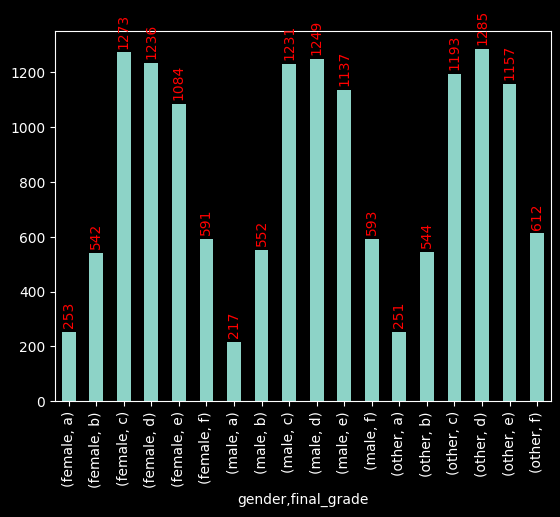

In [17]:
# Pivot table
pivot_table_1=data.groupby(["gender","final_grade"])["final_grade"].count()
ax=pivot_table_1.plot(
    kind="bar"
)
for label in ax.containers:
    ax.bar_label(label,
    rotation=90,
    padding=3,
    color="red")

MODEL

In [18]:
# separate features and terget
features=data.drop(columns="final_grade")
target=data["final_grade"]

In [19]:
# Separate numerical columns
numerical_cols=features.select_dtypes(include="number").columns
numerical_cols

Index(['age', 'study_hours', 'attendance_percentage', 'math_score',
       'science_score', 'english_score', 'overall_score'],
      dtype='str')

In [20]:
# Separate caterical columns
categorical_cols=features.select_dtypes(include="str").columns
categorical_cols

Index(['gender', 'school_type', 'parent_education', 'internet_access',
       'travel_time', 'extra_activities', 'study_method'],
      dtype='str')

In [21]:
# Split data into training and test dataset
x_train,x_test,y_train,y_test=train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=12,
    stratify=target
)

In [22]:
data.shape

(15000, 15)

In [23]:
x_test.shape

(3000, 14)

In [24]:
y_test.shape

(3000,)

In [25]:
# Initiate numerical pipeline
numerical_pipeline=Pipeline([
    ("impute_num",SimpleImputer(strategy='mean')),
    ("scaler",StandardScaler())
])

In [26]:
# Initiate categorical pipeline
categorical_pipeline=Pipeline([
    ("impute_cat",SimpleImputer(strategy='most_frequent')),
    ("encoder",OneHotEncoder(handle_unknown='ignore'))
])

In [27]:
# Combine pipelines
preprocessing=ColumnTransformer([
    ("num",numerical_pipeline,numerical_cols),
    ("cat",categorical_pipeline,categorical_cols)
])

In [28]:
# k_value=[x for x in range(1,251)]
# results=[]
# for k in k_value:
#     model=Pipeline([
#         ("preprocessing",preprocessing),
#         ("model",KNeighborsClassifier(n_neighbors=k))
#     ])
#     scores=cross_val_score(
#         model,
#         x_train,
#         y_train,
#         cv=5,
#         scoring='accuracy'

#     )
#     results.append({
#         "k":k,
#         "score":scores,
#         "cv_score_mean":scores.mean(),
#         "cv_score_std":scores.std()
#     })

In [29]:
# score_table=pd.DataFrame(results)

In [30]:
# sorted_=score_table.sort_values(by="cv_score_mean",ascending=False)
# sorted_.head(20)

In [31]:
# min_=999990
# for list_ in sorted_["score"]:
#     current=list_.std()
#     if current<min_:
#         min_=current
#     print(list_)
# print(min_)

In [32]:
# plt.plot(
#     score_table["k"],
#     score_table["cv_score_mean"]
# )
# plt.show()

In [33]:
# a=score_table["cv_score_mean"].max()
# c=score_table["cv_score_mean"]==a
# score_table.loc[c]

In [34]:
# for val in score_table.loc[c,"score"]:
#     print(val)

In [35]:
# c=score_table["k"]==97
# score_table.loc[c]

In [36]:
# Finaly model training
f_model=Pipeline([
    ("preprocessing",preprocessing),
    ("model",KNeighborsClassifier(n_neighbors=97))
])
f_model.fit(x_train,y_train)
print(f"Training score: {round(f_model.score(x_train,y_train),4)}")

Training score: 0.8007


In [37]:
# Testing
y_predicted=f_model.predict(x_test)
f_model.score(x_train,y_train)
acc=accuracy_score(y_test,y_predicted)
print(f"Testinig score: {round(acc,4)}")

Testinig score: 0.7893


In [38]:
y_predicted

array(['e', 'd', 'e', ..., 'e', 'e', 'c'], shape=(3000,), dtype=object)

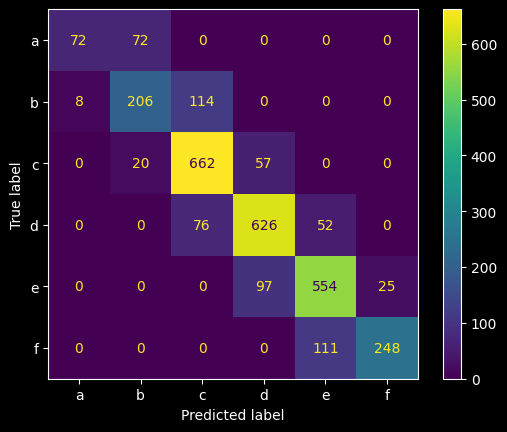

In [39]:
conf=ConfusionMatrixDisplay.from_predictions(y_test,y_predicted)

In [40]:
f_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers c

IMPLEMENT GRIDSEARCHCV

In [41]:
model=Pipeline([
        ("preprocessing",preprocessing),
        ("model",KNeighborsClassifier())
    ])

In [42]:
# parameters
parameters_={
    "model__n_neighbors":[x for x in range(1,251,1)],
    "model__weights":["uniform","distance"],
    "model__metric":["euclidean","manhattan"]
}

In [43]:
# GridSearchCV
grid_=GridSearchCV(
    estimator=model,
    param_grid=parameters_,
    cv=5,
    scoring="accuracy"
)

In [44]:
grid_.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': [1, 2, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and p

In [ ]:
results_=grid_.cv_results_
result_table=pd.DataFrame(results_)
result_table

In [46]:
best_parameters_=grid_.best_params_
best_parameters_

{'model__metric': 'manhattan',
 'model__n_neighbors': 61,
 'model__weights': 'distance'}

In [74]:
# Training final model
final_model=Pipeline(steps=[
("processing",preprocessing),
("model",KNeighborsClassifier(
 metric="manhattan",
 n_neighbors=61,
 weights="distance"
))])

In [75]:
final_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('processing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

In [76]:
predict_=final_model.predict(x_train)

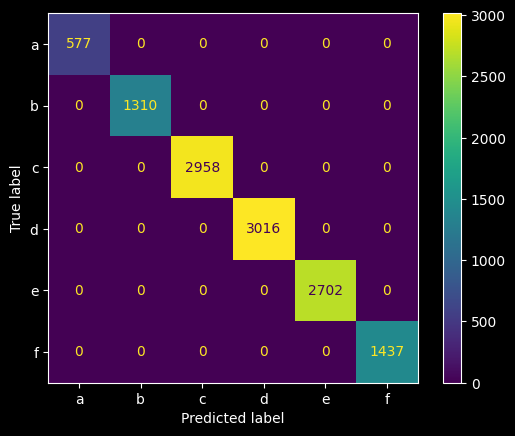

In [77]:
confusion_matrix_training=ConfusionMatrixDisplay.from_predictions(y_train,predict_)

In [78]:
print(classification_report(y_train,predict_))

              precision    recall  f1-score   support

           a       1.00      1.00      1.00       577
           b       1.00      1.00      1.00      1310
           c       1.00      1.00      1.00      2958
           d       1.00      1.00      1.00      3016
           e       1.00      1.00      1.00      2702
           f       1.00      1.00      1.00      1437

    accuracy                           1.00     12000
   macro avg       1.00      1.00      1.00     12000
weighted avg       1.00      1.00      1.00     12000



TESTING

In [79]:
y_predict_=final_model.predict(x_test)

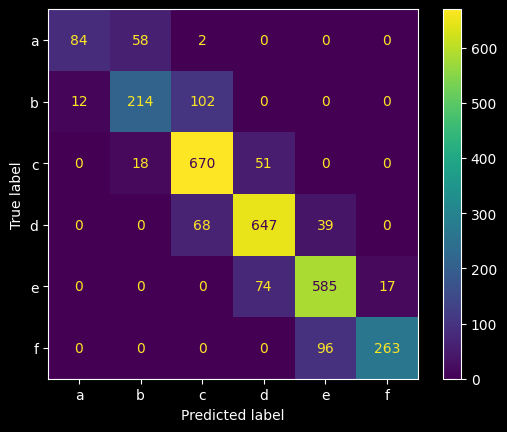

In [53]:
confusion_matrix_training=ConfusionMatrixDisplay.from_predictions(y_test,y_predict_)

In [54]:
print(classification_report(y_test,y_predict_))

              precision    recall  f1-score   support

           a       0.88      0.58      0.70       144
           b       0.74      0.65      0.69       328
           c       0.80      0.91      0.85       739
           d       0.84      0.86      0.85       754
           e       0.81      0.87      0.84       676
           f       0.94      0.73      0.82       359

    accuracy                           0.82      3000
   macro avg       0.83      0.77      0.79      3000
weighted avg       0.82      0.82      0.82      3000

